# QuietCount
Predict 0–3 occupants from ambient sensors. Data: [UCI Room Occupancy Estimation](https://doi.org/10.24432/C5P605). Run training before rerunning the results cells.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from train import TARGET, LABELS, load_data, split

data = load_data()
train, valid, test = split(data)
development = pd.concat([train, valid])
print('Rows:', len(data))
print('Missing cells:', data.isna().sum().sum())
print('Duplicate rows:', data.duplicated().sum())
print('Duplicate timestamps:', data.timestamp.duplicated().sum())
print(pd.crosstab(data.Date, data[TARGET]).to_string())

Rows: 10129
Missing cells: 0
Duplicate rows: 0
Duplicate timestamps: 0
Room_Occupancy_Count     0    1    2    3
Date                                     
2017/12/22             637  205  257  363
2017/12/23            1997  254  398  130
2017/12/24            1064    0    0    0
2017/12/25            1716    0    0    0
2017/12/26            1063    0    0    0
2018/01/10             703    0   93  201
2018/01/11            1048    0    0    0


### Split by recording date
Use whole dates to limit leakage between neighbouring readings. Some dates contain only empty-room readings. Keep January untouched during model selection.

In [2]:
print(pd.DataFrame({
    name: frame[TARGET].value_counts().reindex(LABELS, fill_value=0)
    for name, frame in [('train', train), ('validation', valid), ('test', test)]
}).to_string())

                      train  validation  test
Room_Occupancy_Count                         
0                       637        5840  1751
1                       205         254     0
2                       257         398    93
3                       363         130   201


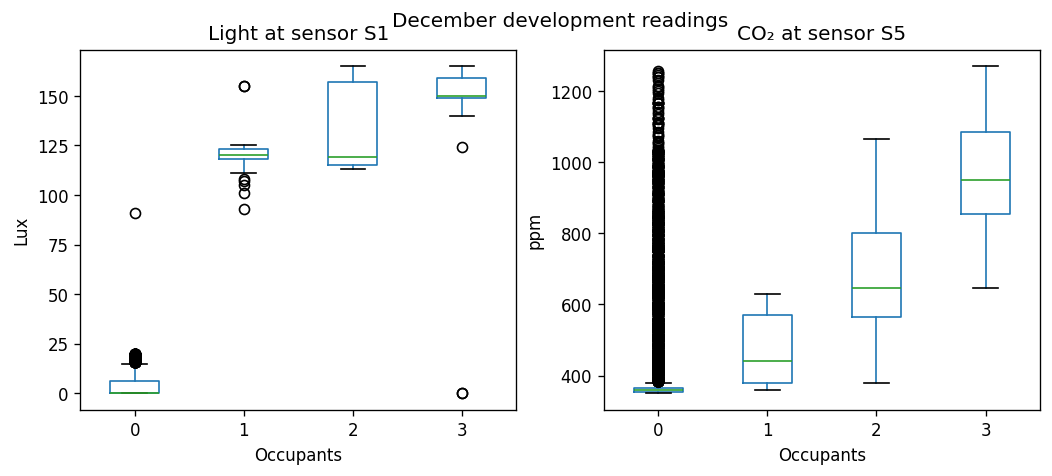

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
development.boxplot(column='S1_Light', by=TARGET, ax=axes[0], grid=False)
development.boxplot(column='S5_CO2', by=TARGET, ax=axes[1], grid=False)
fig.suptitle('December development readings')
axes[0].set(xlabel='Occupants', ylabel='Lux', title='Light at sensor S1')
axes[1].set(xlabel='Occupants', ylabel='ppm', title='CO₂ at sensor S5')
plt.show()

### Model and sensor selection
Compare the majority baseline, logistic regression and random forests. The validation criterion is macro F1. Prefer the smallest sensor set within 0.03 of the best score.

In [4]:
report = json.loads(Path('artifacts/metrics.json').read_text())
results = pd.DataFrame(report['candidates'])
print(results[['id', 'macro_f1', 'accuracy']].sort_values(
    'macro_f1', ascending=False).round(4).to_string(index=False))
print('Baseline validation macro F1:', round(report['validation_baseline']['macro_f1'], 4))
print('Selected:', report['selected']['id'])

                 id  macro_f1  accuracy
 ambient/logistic/-    0.9987    0.9997
    full/logistic/-    0.9896    0.9983
   ambient/forest/4    0.9415    0.9789
   ambient/forest/8    0.9415    0.9787
ambient/forest/None    0.9405    0.9787
   full/forest/None    0.8885    0.9778
      full/forest/8    0.8780    0.9773
      full/forest/4    0.8455    0.9749
   minimal/forest/8    0.7819    0.9678
minimal/forest/None    0.7819    0.9678
   minimal/forest/4    0.7809    0.9677
 minimal/logistic/-    0.7468    0.9618
Baseline validation macro F1: 0.2343
Selected: ambient/logistic/-


### Feature importance on validation
Shuffle one column at a time and measure the drop in validation macro F1. Correlated light channels can substitute for one another, so these values measure model reliance and do not establish causation.

       S1_Light  S2_Light  S3_Light  S4_Light   S5_CO2
count   8084.00   8084.00   8084.00   8084.00  8084.00
mean      29.66     29.19     39.97     15.41   469.75
std       53.90     70.35     61.89     20.91   209.84
min        0.00      0.00      0.00      0.00   350.00
25%        0.00      0.00      0.00      0.00   355.00
50%        0.00      0.00      0.00      0.00   360.00
75%       15.00     19.00     61.00     27.00   485.00
max      165.00    258.00    280.00     74.00  1270.00


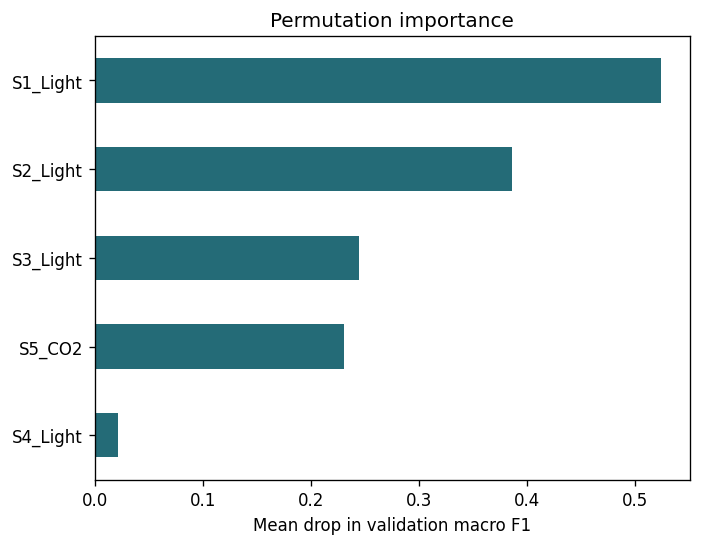

In [5]:
from sklearn.inspection import permutation_importance
from train import FEATURES, estimator_grid
columns = FEATURES[report['selected']['features']]
selected = report['selected']
model = next(candidate for name, params, candidate in estimator_grid()
             if name == selected['model'] and params == selected['parameters'])
model.fit(train[columns], train[TARGET])
importance = permutation_importance(model, valid[columns], valid[TARGET],
                                    scoring='f1_macro', n_repeats=5, random_state=42)
print(development[columns].describe().round(2).to_string())
ranking = pd.Series(importance.importances_mean, index=columns).sort_values()
ranking.plot.barh(color='#246b77', xlabel='Mean drop in validation macro F1')
plt.title('Permutation importance')
plt.show()

### Held-out January recordings
The January set has no one-person readings. Report macro F1 over supported true labels, and include a fixed-four-label score and confusion matrix in the metrics artifact.

Model macro F1: 0.475
Baseline macro F1: 0.308


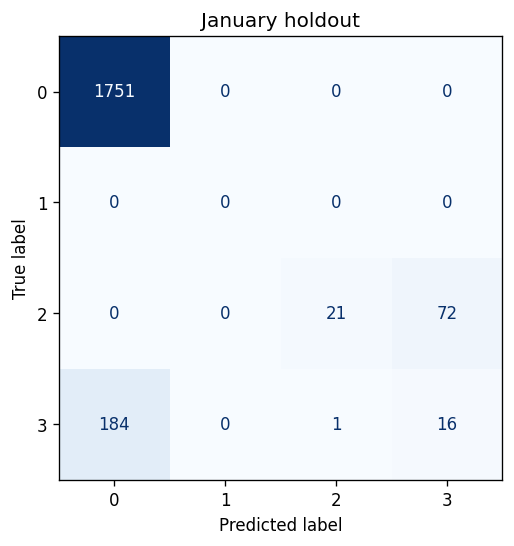

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
holdout = report['test']
print(f"Model macro F1: {holdout['macro_f1']:.3f}")
print(f"Baseline macro F1: {report['test_baseline']['macro_f1']:.3f}")
ConfusionMatrixDisplay(pd.DataFrame(holdout['confusion_matrix']).to_numpy(), display_labels=LABELS).plot(
    cmap='Blues', colorbar=False)
plt.title('January holdout')
plt.show()

The model confused most three-person readings with an empty room. The drop from validation highlights sensitivity to recording sessions. Generalisation needs more sessions and unseen rooms.